<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS11/Tugas-LAB/PEMMESTUGAS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS LAB JS11 - Convolutional Neural Network

Notebook ini berisi dua tugas lab modul JS11:

1. **Tugas 1** - Modifikasi model CNN pada Praktikum 2 (CIFAR-10) sehingga didapatkan akurasi testing lebih dari 80%.
2. **Tugas 2** - Membuat model CNN untuk klasifikasi dataset MNIST.



## Langkah 1 - Load Library

Cukup dijalankan sekali, dipakai oleh Tugas 1 dan Tugas 2.

In [1]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

---
# Tugas 1 - Modifikasi CNN CIFAR-10 (akurasi testing > 80%)

Model dasar Praktikum 2 (Lab 2):

`Conv2D(32) -> MaxPool -> Conv2D(64) -> MaxPool -> Conv2D(64) -> Flatten -> Dense(64) -> Dense(10)` (10 epoch, akurasi sekitar 71%)

Modifikasi yang dilakukan:

1. Konvolusi menggunakan `padding='same'` agar dimensi spasial tidak menyusut terlalu cepat (pola VGG-style).
2. Setiap Conv2D diikuti `BatchNormalization` + `Activation('relu')` (urutan Conv -> BN -> ReLU) supaya training lebih stabil dan cepat konvergen.
3. Blok konvolusi diperdalam: Conv2D(32, 32) -> Conv2D(64, 64) -> Conv2D(128) dengan 3 blok `MaxPooling2D`.
4. `Dropout` ditambahkan setelah setiap `MaxPooling2D` (0.25) dan sebelum output layer (0.5) untuk meredam overfitting.
5. Dense layer diperbesar dari 64 menjadi 128 unit.
6. Jumlah epoch dinaikkan dari 10 menjadi 30.

Optimizer, loss (`SparseCategoricalCrossentropy(from_logits=True)`), dan alur kode (load data -> arsitektur -> compile -> fit -> evaluasi) tetap mengikuti Praktikum 2.

### Langkah 2 - Unduh Dataset CIFAR

In [2]:
tf.random.set_seed(42)

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 967s 6us/step


### Langkah 3 - Verifikasi Data

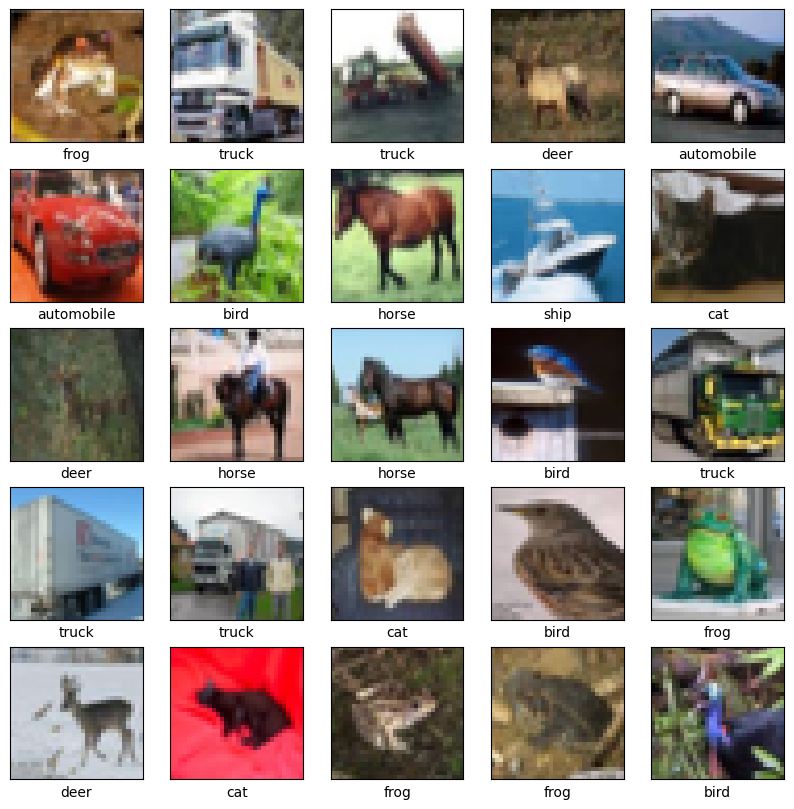

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.savefig('cifar10_samples.png', dpi=150, bbox_inches='tight')
plt.show()

### Langkah 4 - Buat Model CNN (hasil modifikasi)

#### Langkah 4.1 - 4.3. Buat Layer Konvolusi dan Fully Connected

In [4]:
model = models.Sequential()

# Blok konvolusi 1
model.add(layers.Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3)))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.Conv2D(32, (3, 3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.25))

# Blok konvolusi 2
model.add(layers.Conv2D(64, (3, 3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.Conv2D(64, (3, 3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.25))

# Blok konvolusi 3
model.add(layers.Conv2D(128, (3, 3), padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Activation('relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.25))

# Klasifikasi
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(10))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Langkah 4.4. - Cek Arsitektur Model CNN

In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 404,266 (1.54 MB)

 Trainable params: 403,626 (1.54 MB)

 Non-trainable params: 640 (2.50 KB)

#### Langkah 4.5. - Compile Model CNN

In [6]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### Langkah 5 - Fit Model

Callback hanya menyimpan model terbaik (val_accuracy tertinggi) dan log per-epoch, tidak mengubah proses training.

In [7]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint('cifar10_best_model.keras',
                                       monitor='val_accuracy',
                                       save_best_only=True,
                                       verbose=0),
    tf.keras.callbacks.CSVLogger('cifar10_training_log.csv', append=False),
]

history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(test_images, test_labels),
                    callbacks=callbacks,
                    verbose=2)

Epoch 1/30
1563/1563 - 47s - 30ms/step - accuracy: 0.2420 - loss: 1.9642 - val_accuracy: 0.3371 - val_loss: 1.7289
Epoch 2/30
1563/1563 - 9s - 6ms/step - accuracy: 0.3187 - loss: 1.7240 - val_accuracy: 0.4878 - val_loss: 1.4710
Epoch 3/30
1563/1563 - 9s - 6ms/step - accuracy: 0.3692 - loss: 1.6046 - val_accuracy: 0.5443 - val_loss: 1.3425
Epoch 4/30
1563/1563 - 9s - 6ms/step - accuracy: 0.4163 - loss: 1.5176 - val_accuracy: 0.5431 - val_loss: 1.2542
Epoch 5/30
1563/1563 - 9s - 6ms/step - accuracy: 0.4461 - loss: 1.4520 - val_accuracy: 0.6514 - val_loss: 1.1202
Epoch 6/30
1563/1563 - 9s - 6ms/step - accuracy: 0.4883 - loss: 1.3551 - val_accuracy: 0.6645 - val_loss: 0.9999
Epoch 7/30
1563/1563 - 9s - 6ms/step - accuracy: 0.5319 - loss: 1.2500 - val_accuracy: 0.6833 - val_loss: 0.9649
Epoch 8/30
1563/1563 - 9s - 6ms/step - accuracy: 0.5717 - loss: 1.1651 - val_accuracy: 0.6030 - val_loss: 1.0770
Epoch 9/30
1563/1563 - 9s - 6ms/step - accuracy: 0.6027 - loss: 1.0832 - val_accuracy: 0.6696 

### Langkah 6 - Evaluasi Model

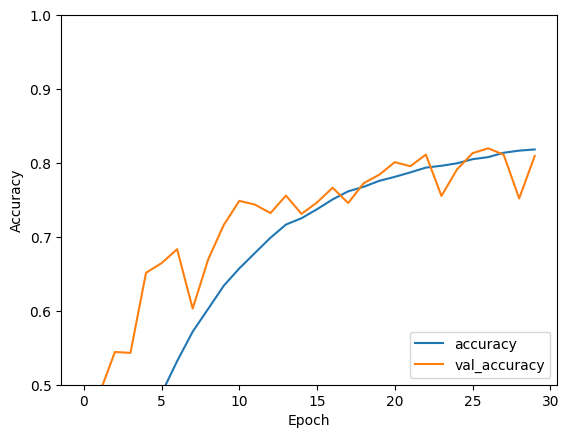

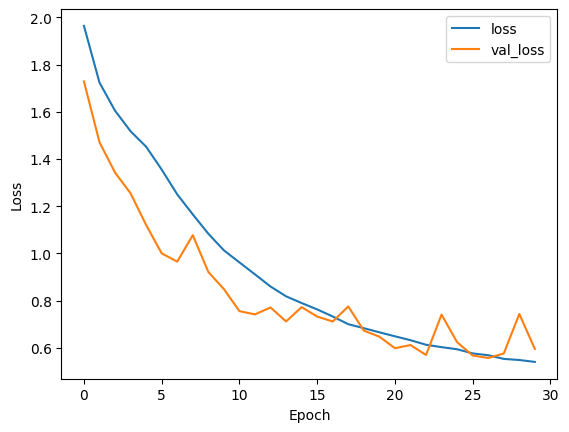

313/313 - 1s - 3ms/step - accuracy: 0.8095 - loss: 0.5947


In [8]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.savefig('cifar10_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.savefig('cifar10_loss.png', dpi=150, bbox_inches='tight')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

### Langkah 7 - Cetak Hasil Akurasi

In [9]:
print('test_loss:', test_loss)
print('test_acc:', test_acc)
print('Akurasi testing > 80%?', 'YA' if test_acc > 0.80 else 'BELUM, perlu dilanjutkan training')

# Simpan hasil untuk laporan
import json
with open('cifar10_history.json', 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f, indent=2)

model.save('cifar10_final_model.keras')
print('Model disimpan ke cifar10_final_model.keras')

test_loss: 0.5947048664093018
test_acc: 0.809499979019165
Akurasi testing > 80%? YA
Model disimpan ke cifar10_final_model.keras


---
# Tugas 2 - Model CNN untuk Klasifikasi Dataset MNIST



### Langkah 2 - Unduh Dataset (MNIST, menggantikan CIFAR-10)

In [10]:
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

train_images = train_images.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
test_images = test_images.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Langkah 3 - Verifikasi Data

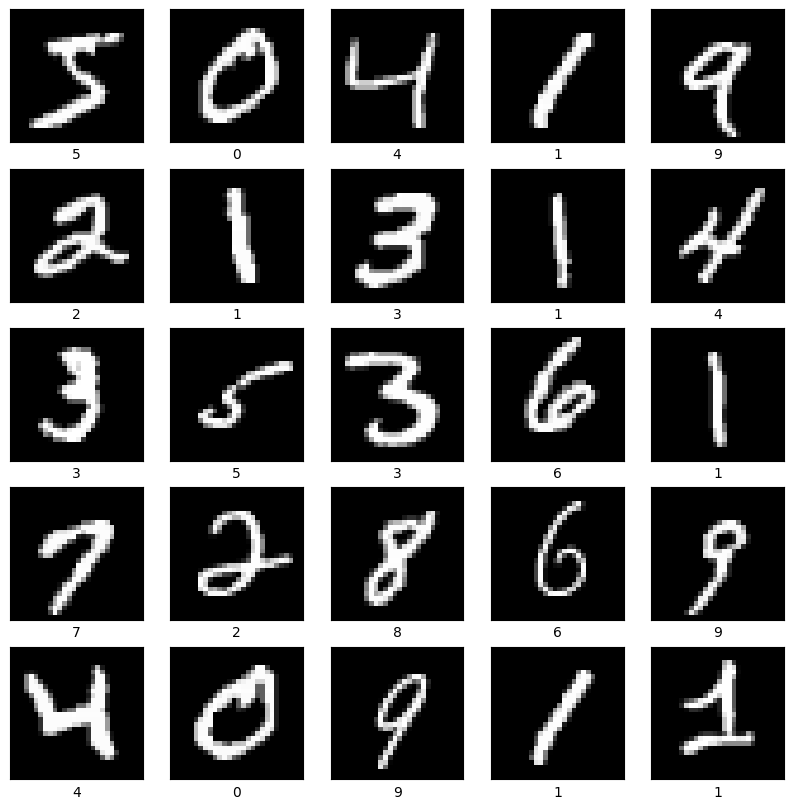

In [11]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(train_labels[i])
plt.savefig('mnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()

### Langkah 4 - Buat Model CNN

#### Langkah 4.1 - 4.3. Buat Layer Konvolusi dan Fully Connected

In [12]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

#### Langkah 4.4. - Cek Arsitektur Model CNN

In [13]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

#### Langkah 4.5. - Compile Model CNN

In [14]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### Langkah 5 - Fit Model

In [15]:
history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels),
                    verbose=2)

Epoch 1/10
1875/1875 - 21s - 11ms/step - accuracy: 0.9562 - loss: 0.1429 - val_accuracy: 0.9834 - val_loss: 0.0544
Epoch 2/10
1875/1875 - 7s - 4ms/step - accuracy: 0.9864 - loss: 0.0443 - val_accuracy: 0.9869 - val_loss: 0.0404
Epoch 3/10
1875/1875 - 8s - 4ms/step - accuracy: 0.9905 - loss: 0.0305 - val_accuracy: 0.9898 - val_loss: 0.0318
Epoch 4/10
1875/1875 - 7s - 4ms/step - accuracy: 0.9923 - loss: 0.0238 - val_accuracy: 0.9888 - val_loss: 0.0354
Epoch 5/10
1875/1875 - 8s - 4ms/step - accuracy: 0.9943 - loss: 0.0172 - val_accuracy: 0.9878 - val_loss: 0.0388
Epoch 6/10
1875/1875 - 7s - 4ms/step - accuracy: 0.9953 - loss: 0.0144 - val_accuracy: 0.9899 - val_loss: 0.0348
Epoch 7/10
1875/1875 - 8s - 4ms/step - accuracy: 0.9963 - loss: 0.0115 - val_accuracy: 0.9899 - val_loss: 0.0400
Epoch 8/10
1875/1875 - 8s - 4ms/step - accuracy: 0.9967 - loss: 0.0100 - val_accuracy: 0.9909 - val_loss: 0.0369
Epoch 9/10
1875/1875 - 7s - 4ms/step - accuracy: 0.9965 - loss: 0.0108 - val_accuracy: 0.9894 

### Langkah 6 - Evaluasi Model

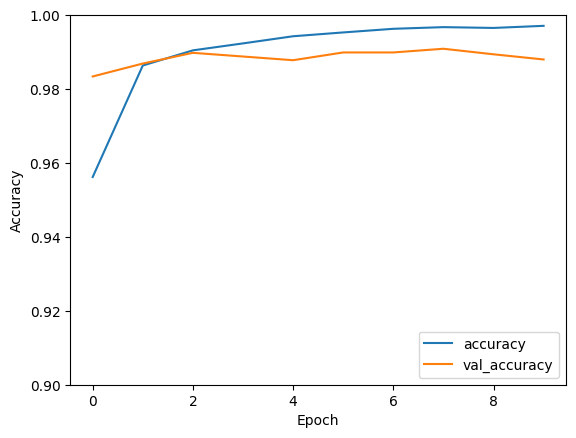

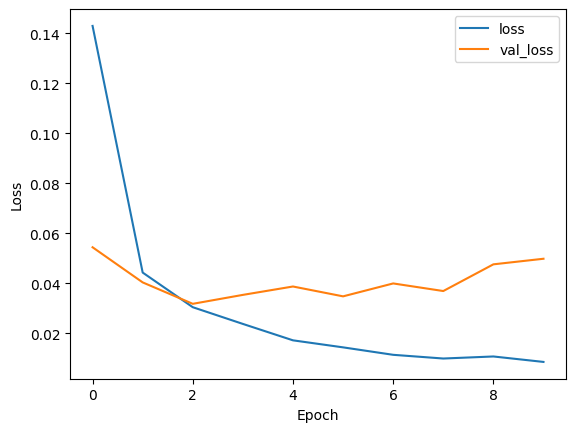

313/313 - 1s - 3ms/step - accuracy: 0.9880 - loss: 0.0498


In [16]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.9, 1])
plt.legend(loc='lower right')
plt.savefig('mnist_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.savefig('mnist_loss.png', dpi=150, bbox_inches='tight')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

### Langkah 7 - Cetak Hasil Akurasi

In [17]:
print('test_loss:', test_loss)
print('test_acc:', test_acc)

# Simpan hasil untuk laporan
import json
with open('mnist_history.json', 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f, indent=2)

model.save('mnist_cnn_model.keras')
print('Model disimpan ke mnist_cnn_model.keras')

test_loss: 0.04984666779637337
test_acc: 0.9879999756813049
Model disimpan ke mnist_cnn_model.keras
